In [2]:

import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("data/salesdaily.csv")
df["datum"] = pd.to_datetime(df["datum"])

# Identify drug-category columns (ATC codes)
metadata_columns = ["datum", "Year", "Month", "Hour", "Weekday Name"]
drug_columns = [
    col for col in df.columns
    if col not in metadata_columns
    and pd.api.types.is_numeric_dtype(df[col])
]

1. Total Sales by Drug Category:
N02BE    63005.402708
N05B     18645.737500
R03      11608.822917
M01AB    10600.937083
M01AE     8204.618646
N02BA     8172.209000
R06       6107.817500
N05C      1249.958333
dtype: float64


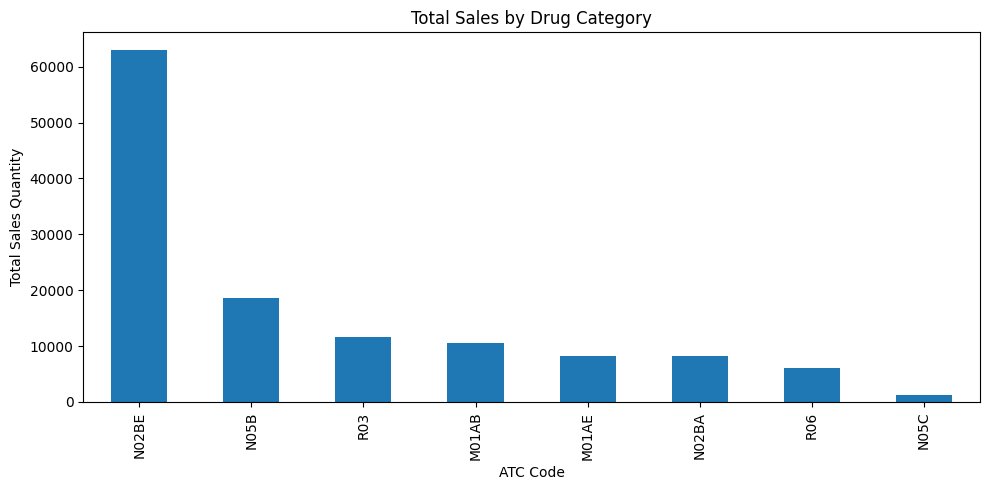

In [3]:
# 1. Total sales quantities for each drug category (ATC code)
total_sales = df[drug_columns].sum().sort_values(ascending=False)

print("1. Total Sales by Drug Category:")
print(total_sales)

total_sales.plot(kind="bar", figsize=(10, 5),
                 title="Total Sales by Drug Category")
plt.ylabel("Total Sales Quantity")
plt.xlabel("ATC Code")
plt.tight_layout()
plt.show()

In [4]:
print(
    "Individual drug brands cannot be ranked because "
    "salesdaily.csv contains ATC categories, not brand names."
)

Individual drug brands cannot be ranked because salesdaily.csv contains ATC categories, not brand names.


In [5]:
# 2. Individual drug brands with the highest total sales
print("\n2. Highest-Selling Individual Drug Brands:")
print(
    "Cannot be determined from this dataset because it contains "
    "ATC category columns rather than individual drug brand names."
)


2. Highest-Selling Individual Drug Brands:
Cannot be determined from this dataset because it contains ATC category columns rather than individual drug brand names.


In [6]:
# 3. Top 3 drug categories in January 2015, July 2016, September 2017
periods = [(2015, 1), (2016, 7), (2017, 9)]

for year, month in periods:
    period_data = df[
        (df["datum"].dt.year == year) &
        (df["datum"].dt.month == month)
    ]

    top_3 = period_data[drug_columns].sum().nlargest(3)

    print(f"\n3. Top 3 Drug Categories: {year}-{month:02d}")
    print(top_3)



3. Top 3 Drug Categories: 2015-01
N02BE    1044.24
N05B      463.00
R03       177.25
dtype: float64

3. Top 3 Drug Categories: 2016-07
N02BE    652.362000
N05B     240.000000
M01AB    194.528333
dtype: float64

3. Top 3 Drug Categories: 2017-09
N02BE    863.75
N05B     223.00
R03      139.00
dtype: float64



4. Highest-Selling Drug Category in 2017:
N02BE    9258.804833
dtype: float64


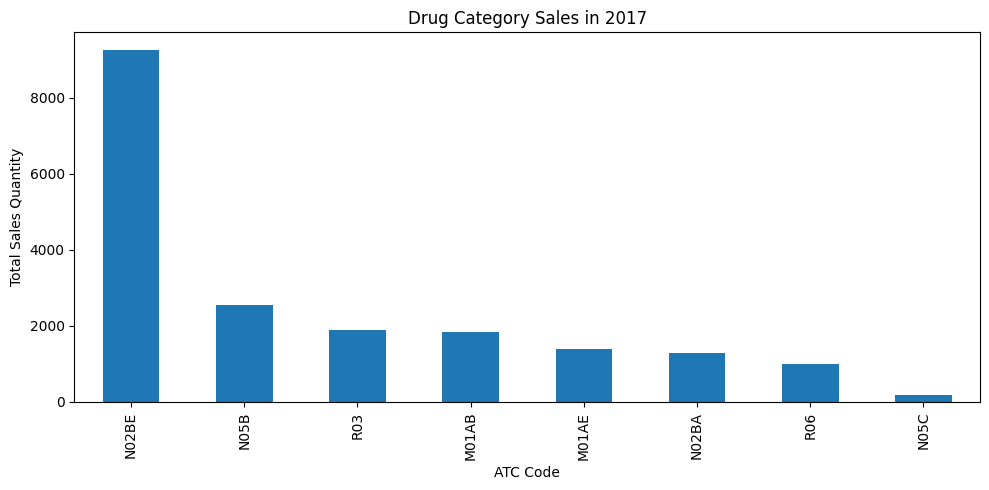

In [7]:
# 4. Drug category with the highest total sales in 2017
data_2017 = df[df["datum"].dt.year == 2017]
sales_2017 = data_2017[drug_columns].sum().sort_values(
    ascending=False
)

print("\n4. Highest-Selling Drug Category in 2017:")
print(sales_2017.head(1))

sales_2017.plot(kind="bar", figsize=(10, 5),
                title="Drug Category Sales in 2017")
plt.ylabel("Total Sales Quantity")
plt.xlabel("ATC Code")
plt.tight_layout()
plt.show()



5. Average Daily Sales by Drug Category:
N02BE    29.917095
N05B      8.853627
R03       5.512262
M01AB     5.033683
M01AE     3.895830
N02BA     3.880441
R06       2.900198
N05C      0.593522
dtype: float64

Highest Average Daily Sales: N02BE = 29.917095303105413


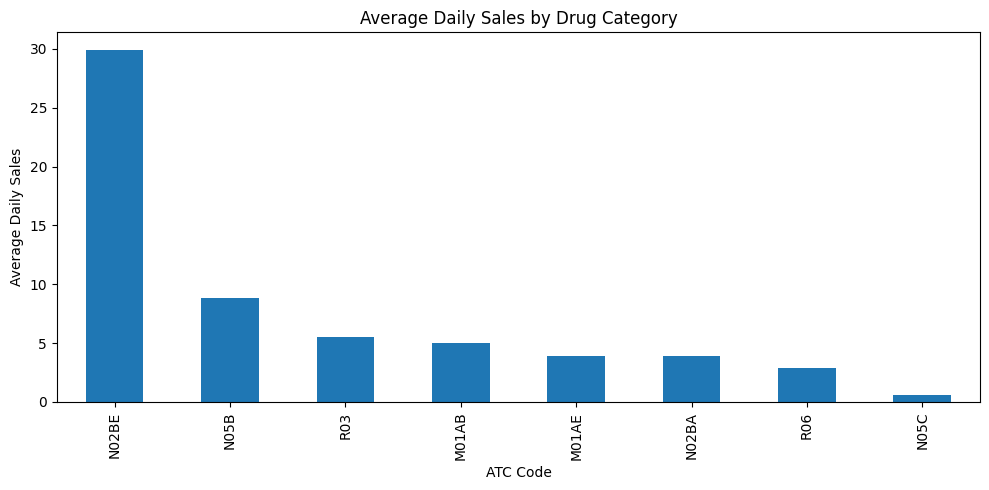

In [8]:
# 5. Drug category with the highest average daily sales
average_sales = df[drug_columns].mean().sort_values(
    ascending=False
)

print("\n5. Average Daily Sales by Drug Category:")
print(average_sales)

print(
    "\nHighest Average Daily Sales:",
    average_sales.idxmax(),
    "=",
    average_sales.max()
)

average_sales.plot(kind="bar", figsize=(10, 5),
                   title="Average Daily Sales by Drug Category")
plt.ylabel("Average Daily Sales")
plt.xlabel("ATC Code")
plt.tight_layout()
plt.show()



6. Average Daily R03 Sales by Month:
Jan    6.835980
Feb    6.896943
Mar    6.290323
Apr    5.771528
May    5.006944
Jun    4.350000
Jul    2.956989
Aug    3.102151
Sep    4.402315
Oct    7.208589
Nov    6.226667
Dec    7.916129
Name: R03, dtype: float64

Month with Highest Average R03 Sales: Dec = 7.916129032258064


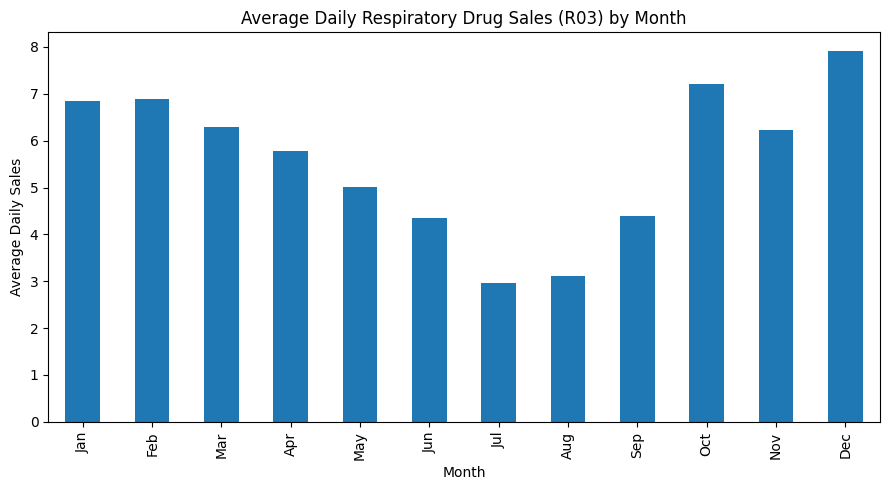

In [9]:
# 6. Do respiratory drugs (R03) sell more during specific months?
if "R03" in df.columns:
    monthly_r03 = df.groupby(
        df["datum"].dt.month
    )["R03"].mean()

    month_names = [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ]

    monthly_r03.index = [
        month_names[m - 1] for m in monthly_r03.index
    ]

    print("\n6. Average Daily R03 Sales by Month:")
    print(monthly_r03)

    print(
        "\nMonth with Highest Average R03 Sales:",
        monthly_r03.idxmax(),
        "=",
        monthly_r03.max()
    )

    monthly_r03.plot(
        kind="bar",
        figsize=(9, 5),
        title="Average Daily Respiratory Drug Sales (R03) by Month"
    )
    plt.ylabel("Average Daily Sales")
    plt.xlabel("Month")
    plt.tight_layout()
    plt.show()
else:
    print("\n6. R03 column not found in the dataset.")
